# Bongkar Isi Foto: Metadata dan Angka Representasi Gambar

0. Import library dan tentukan file

In [1]:
import os                      # os: berinteraksi dengan sistem file (cek ukuran file)
import hashlib                 # hashlib: membuat sidik jari (hash) file
import numpy as np             # numpy: mengolah gambar sebagai array angka
import matplotlib.pyplot as plt  # matplotlib: menampilkan gambar dan grafik
from PIL import Image, ImageFilter          # PIL (Pillow): membuka dan memproses gambar
from PIL.ExifTags import TAGS, GPSTAGS      # kamus: kode angka EXIF -> nama tag yang terbaca manusia

PATH = "foto1.jpg"             # nama file foto (harus satu folder dengan notebook)

1. Tampilkan foto

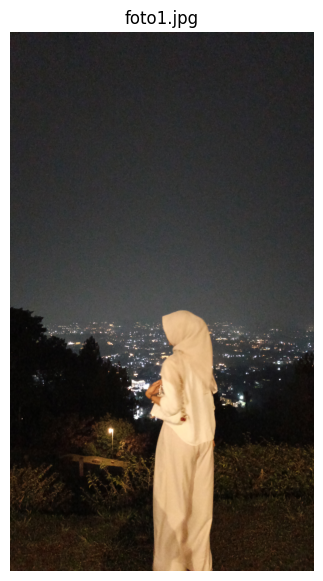

In [2]:
img = Image.open(PATH)          # buka file gambar; hasilnya objek Image (belum dibaca penuh)
plt.figure(figsize=(4, 7))     # buat kanvas ukuran 4x7 inci (portrait)
plt.imshow(img)                # gambar foto ke kanvas
plt.axis("off")                # sembunyikan sumbu x dan y
plt.title("foto1.jpg")         # judul gambar
plt.show()                     # tampilkan

2. Info file

File di komputer pada dasarnya hanya deretan **byte**. Dari byte-byte itu kita bisa mengambil ukuran, sidik jari (hash), dan tipe aslinya.

In [3]:
ukuran = os.path.getsize(PATH)           # ukuran file dalam byte
print("Ukuran file :", ukuran, "byte =", round(ukuran / 1024, 1), "KB")

with open(PATH, "rb") as f:              # buka file mode 'rb' = read binary (baca byte mentah)
    data = f.read()                      # baca seluruh isi file ke variabel data

print("SHA-256     :", hashlib.sha256(data).hexdigest())
# SHA-256 = sidik jari unik file. Satu piksel berubah saja, hash-nya ikut berubah total.

print("Magic bytes :", data[:4].hex())
# 4 byte pertama file. FFD8FFE0 = tanda khas JPEG, jadi tipe file tidak bisa dipalsukan hanya dengan ganti ekstensi.

Ukuran file : 2503128 byte = 2444.5 KB
SHA-256     : ee68ae4f1fe18ec3448ab0fb99e850282227e80de07f4f7e1667139a7c7039f1
Magic bytes : ffd8ffe1


3. Metadata
Ada dua sumber utama:
- Properti dasar: format, ukuran, mode warna
- EXIF: data kamera, waktu, lokasi GPS (kalau ada)

In [4]:
print("Format :", img.format)                  # jenis file (JPEG, PNG, dll)
print("Ukuran :", img.size, "(lebar x tinggi)")   # dalam piksel
print("Mode   :", img.mode)                      # RGB = 3 channel warna (Red, Green, Blue)

for k, v in img.info.items():                    # img.info = data tambahan bawaan file (JFIF, ICC profile, dll)
    if k == "icc_profile":
        v = f"{len(v)} byte"                     # ICC profile panjang, jadi tampilkan ukurannya saja
    print("Info   :", k, "=", v)

Format : JPEG
Ukuran : (2160, 3840) (lebar x tinggi)
Mode   : RGB
Info   : exif = b'Exif\x00\x00II*\x00\x08\x00\x00\x00\x13\x00\x00\x01\x03\x00\x01\x00\x00\x00p\x08\x00\x00\x01\x01\x03\x00\x01\x00\x00\x00\x00\x0f\x00\x00\x0e\x01\x02\x00 \x00\x00\x00\xf2\x00\x00\x00\x0f\x01\x02\x00 \x00\x00\x00\x12\x01\x00\x00\x10\x01\x02\x00$\x00\x00\x002\x01\x00\x00\x12\x01\x03\x00\x01\x00\x00\x00\x00\x00\x00\x00\x1a\x01\x05\x00\x01\x00\x00\x00V\x01\x00\x00\x1b\x01\x05\x00\x01\x00\x00\x00^\x01\x00\x00(\x01\x03\x00\x01\x00\x00\x00\x02\x00\x00\x001\x01\x02\x00 \x00\x00\x00f\x01\x00\x002\x01\x02\x00\x14\x00\x00\x00\x86\x01\x00\x00\x13\x02\x03\x00\x01\x00\x00\x00\x02\x00\x00\x00 \x02\x04\x00\x01\x00\x00\x00\x00\x00\x00\x00!\x02\x04\x00\x01\x00\x00\x00\x00\x00\x00\x00"\x02\x04\x00\x01\x00\x00\x00\x00\x00\x00\x00#\x02\x04\x00\x01\x00\x00\x00\x00\x00\x00\x00$\x02\x04\x00\x01\x00\x00\x00\x00\x00\x00\x00%\x02\x02\x00 \x00\x00\x00\x9a\x01\x00\x00i\x87\x04\x00\x01\x00\x00\x00\xba\x01\x00\x00\xf9\x07\x00\x00\x00\

In [5]:
exif = img.getexif()                              # ambil blok EXIF (kalau ada)
print("Jumlah tag EXIF:", len(exif))

for tag_id, val in exif.items():                  # tiap tag berupa pasangan (kode angka, nilai)
    print(TAGS.get(tag_id, tag_id), ":", val)     # terjemahkan kode ke nama (misal 271 -> Make)

gps = exif.get_ifd(0x8825)                        # 0x8825 = alamat blok GPS dalam standar EXIF
for tag_id, val in gps.items():
    print("GPS", GPSTAGS.get(tag_id, tag_id), ":", val)

if len(exif) == 0:
    print("EXIF kosong: kemungkinan sudah dihapus WhatsApp/sosmed atau terkompresi saat upload.")

Jumlah tag EXIF: 19
ImageWidth : 2160
ImageLength : 3840
ImageDescription :                                
Make : TECNO                          
Model : TECNO CM5                          
Orientation : 0
YCbCrPositioning : 2
XResolution : 72.0
YResolution : 72.0
544 : 0
545 : 0
546 : 0
547 : 0
548 : 0
549 :                                
ResolutionUnit : 2
Software : MediaTek Camera Application    
DateTime : 2026:09:26 23:29:47
ExifOffset : 442


4. Gambar menjadi angka

Foto = matriks 3 dimensi: `(tinggi, lebar, channel)`. Setiap piksel punya 3 angka (R, G, B) dengan rentang 0 sampai 255.

In [6]:
arr = np.array(img)                       # ubah gambar jadi array numpy
print("Shape        :", arr.shape)      # (tinggi, lebar, 3)
print("Tipe data    :", arr.dtype)      # uint8 = bilangan bulat 0-255 (8 bit)
print("Total piksel :", arr.shape[0] * arr.shape[1])
print("Total angka  :", arr.size)       # piksel x 3 channel
print("Piksel [0,0] (pojok kiri atas):", arr[0, 0])
tengah = arr[arr.shape[0] // 2, arr.shape[1] // 2]   # // = pembagian bulat
print("Piksel tengah:", tengah)

Shape        : (3840, 2160, 3)
Tipe data    : uint8
Total piksel : 8294400
Total angka  : 24883200
Piksel [0,0] (pojok kiri atas): [50 60 36]
Piksel tengah: [84 85 87]


5. Statistik per channel

In [7]:
for i, nama in enumerate(["R", "G", "B"]):     # i = 0,1,2 ; nama = huruf channel
    c = arr[:, :, i]                              # ambil satu channel saja (semua baris, semua kolom)
    print(f"{nama}: min={c.min()}  max={c.max()}  mean={c.mean():.2f}  "
          f"median={np.median(c):.0f}  std={c.std():.2f}")
# min/max = terendah/tertinggi, mean = rata-rata, median = nilai tengah,
# std = standar deviasi (seberapa menyebar nilainya)

R: min=1  max=255  mean=59.97  median=45  std=55.01
G: min=0  max=255  mean=54.17  median=43  std=45.86
B: min=0  max=255  mean=47.74  median=43  std=36.73


In [8]:
gray = np.array(img.convert("L"))           # "L" = grayscale: 1 angka per piksel (0 hitam, 255 putih)

print(f"Kecerahan rata-rata: {gray.mean():.2f} / 255 = {gray.mean() / 255 * 100:.1f}%")
print("Piksel gelap  (<50) :", f"{(gray < 50).mean() * 100:.1f}%")
print("Piksel terang (>200):", f"{(gray > 200).mean() * 100:.1f}%")
# (gray < 50) menghasilkan array True/False; .mean() dari True/False = proporsi True

Kecerahan rata-rata: 55.16 / 255 = 21.6%
Piksel gelap  (<50) : 61.5%


Piksel terang (>200): 2.7%


6. Histogram

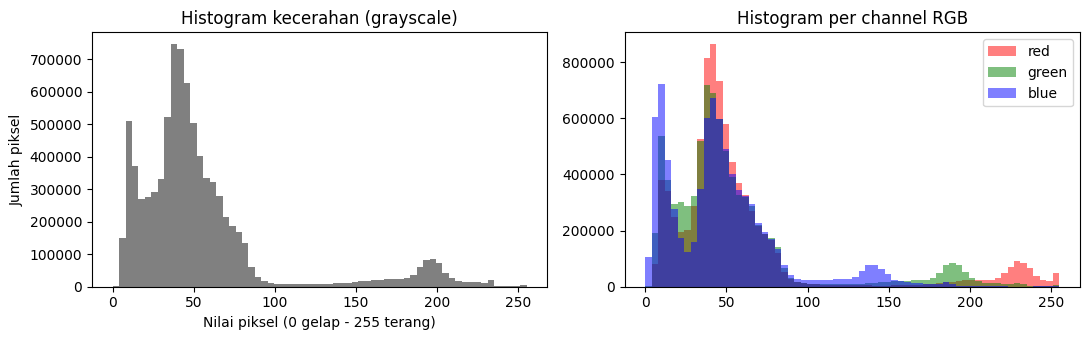

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

ax[0].hist(gray.ravel(), bins=64, range=(0, 255), color="gray")   # ravel() = ratakan array 2D jadi 1D
ax[0].set_title("Histogram kecerahan (grayscale)")
ax[0].set_xlabel("Nilai piksel (0 gelap - 255 terang)")
ax[0].set_ylabel("Jumlah piksel")

for i, warna in enumerate(["red", "green", "blue"]):               # satu garis per channel
    ax[1].hist(arr[:, :, i].ravel(), bins=64, range=(0, 255), color=warna, alpha=0.5, label=warna)
ax[1].set_title("Histogram per channel RGB")
ax[1].legend()

plt.tight_layout()
plt.show()
# Grafik menumpuk di kiri = foto gelap (malam). Bukit kecil di kanan = area terang (baju putih, lampu).

In [10]:
hist, _ = np.histogram(gray, bins=8, range=(0, 256))   # bagi 0-255 jadi 8 kelompok
for i, h in enumerate(hist):
    persen = h / gray.size * 100
    print(f"{i*32:3d}-{i*32+31:3d} | {persen:5.1f}% {'#' * int(persen / 2)}")

  0- 31 |  26.5% #############
 32- 63 |  50.5% #########################
 64- 95 |  13.2% ######
 96-127 |   0.8% 
128-159 |   1.2% 
160-191 |   2.9% #
192-223 |   4.3% ##
224-255 |   0.7% 


7. Warna dominan

(39, 36, 33) 27.4%
(22, 16, 11) 22.6%
(50, 50, 49) 22.4%
(67, 68, 68) 18.3%
(175, 148, 117) 9.3%


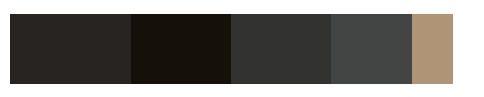

In [11]:
kecil = img.resize((100, 100)).quantize(colors=5).convert("RGB")
# resize: perkecil supaya cepat | quantize(5): sederhanakan semua warna menjadi 5 warna

warna, jumlah = np.unique(np.array(kecil).reshape(-1, 3), axis=0, return_counts=True)
# reshape(-1,3): jadikan daftar piksel | unique: cari warna berbeda + hitung kemunculannya

urut = np.argsort(-jumlah)                 # urutan indeks dari yang paling banyak muncul
fig, ax = plt.subplots(figsize=(6, 1))
for i, idx in enumerate(urut):
    rgb = tuple(int(x) for x in warna[idx])
    persen = jumlah[idx] / jumlah.sum() * 100
    print(rgb, f"{persen:.1f}%")
    ax.barh(0, persen, left=sum(jumlah[urut[:i]]) / jumlah.sum() * 100, color=np.array(rgb) / 255)
ax.axis("off")
plt.show()

8. Kecerahan per zona dan estimasi noise

In [12]:
h = arr.shape[0]                                  # tinggi gambar
zona = [("Atas (0-50%)", 0, h // 2),
        ("Tengah (50-75%)", h // 2, h * 3 // 4),
        ("Bawah (75-100%)", h * 3 // 4, h)]
for nama, a, b in zona:
    print(f"{nama:18s}: {gray[a:b].mean():.2f}")   # rata-rata kecerahan tiap potongan horizontal

Atas (0-50%)      : 48.25
Tengah (50-75%)   : 68.21
Bawah (75-100%)   : 55.94


In [13]:
blur = np.array(img.convert("L").filter(ImageFilter.GaussianBlur(2)))   # versi buram
noise = np.abs(gray.astype(int) - blur).std()
# astype(int) penting: uint8 tidak bisa negatif, jadi hasil pengurangan bisa 'melompat' (overflow)
print("Estimasi noise:", round(float(noise), 2))
# Semakin besar selisih asli vs buram, semakin banyak butiran/noise (ciri foto malam ISO tinggi).

Estimasi noise: 2.82
